<a href="https://colab.research.google.com/github/tranduchoa518-lang/fake-news-detection/blob/main/notebooks/09_model_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
!pip install -q pandas numpy matplotlib scikit-learn

In [18]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
RESULT_DIR = "/content/drive/MyDrive/fake-news-detection/results"

files = [
    "naive_bayes_metrics.json",
    "cnn_metrics.json",
    "rnn_metrics.json",
    "bert_metrics.json"
]

all_results = []

for file in files:
    path = os.path.join(RESULT_DIR, file)

    if os.path.exists(path):
        with open(path, "r") as f:
            all_results.append(json.load(f))
    else:
        print("Chưa tìm thấy:", file)

df = pd.DataFrame(all_results)

print(df)

Chưa tìm thấy: naive_bayes_metrics.json
      Model  Accuracy  Precision    Recall  F1-score
0       CNN  0.976527   0.962557  0.992993  0.977538
1  RNN-LSTM  0.967009   0.967510  0.968379  0.967945
2      BERT  0.993716   0.995137  0.992634  0.993884


In [20]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score"
]

comparison = df.set_index("Model")[metrics]

print("BẢNG SO SÁNH CÁC MÔ HÌNH")
display(comparison.round(4))

BẢNG SO SÁNH CÁC MÔ HÌNH


,Accuracy,Precision,Recall,F1-score
Model,,,,
CNN,0.9765,0.9626,0.9930,0.9775
RNN-LSTM,0.9670,0.9675,0.9684,0.9679
BERT,0.9937,0.9951,0.9926,0.9939


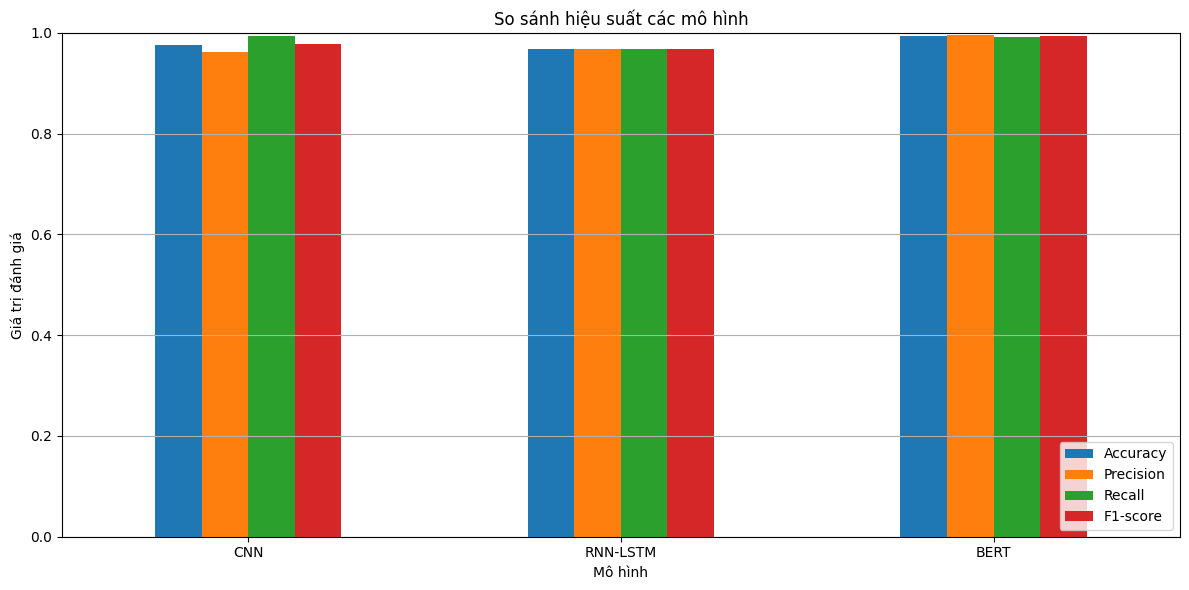

In [21]:
comparison.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("So sánh hiệu suất các mô hình")
plt.xlabel("Mô hình")
plt.ylabel("Giá trị đánh giá")
plt.legend(loc="lower right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [22]:
best_model = df.loc[df["F1-score"].idxmax()]

print("MÔ HÌNH CÓ F1-SCORE CAO NHẤT")
print("Tên mô hình:", best_model["Model"])
print("Accuracy:", best_model["Accuracy"])
print("Precision:", best_model["Precision"])
print("Recall:", best_model["Recall"])
print("F1-score:", best_model["F1-score"])

MÔ HÌNH CÓ F1-SCORE CAO NHẤT
Tên mô hình: BERT
Accuracy: 0.993715922742815
Precision: 0.9951368876080692
Recall: 0.9926338483650736
F1-score: 0.9938837920489296


In [23]:
comparison.to_csv(
    f"{RESULT_DIR}/model_comparison.csv"
)

print("Đã lưu bảng so sánh mô hình!")

Đã lưu bảng so sánh mô hình!
